# 04 — Label-blind anomaly detection and synthetic evaluation

Synthetic data only. Seed 42; session-level analysis. Ground truth is reserved for evaluation.

## Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

## Config

In [2]:
ROOT = Path.cwd() if (Path.cwd() / 'PROJECT_SPEC.md').exists() else Path.cwd().parent
RAW = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed'
PROCESSED.mkdir(parents=True, exist_ok=True)
SEED = 42
ALPHA, POWER = 0.05, 0.80
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')
pd.set_option('display.max_columns', 50)

## Data Cleaning and Preprocessing

In [3]:
features = pd.read_csv(PROCESSED / 'session_features.csv')
print(f'Total Rows: {len(features):,}; Total Columns: {features.shape[1]}')
display(features.isna().sum().rename('null_count').to_frame())
print('Duplicate rows:', features.duplicated().sum(), '; Duplicate session IDs:', features.session_id.duplicated().sum())
assert features.session_id.is_unique and features[['session_id', 'user_id']].notna().all().all()

Total Rows: 20,000; Total Columns: 39


,null_count
session_id,0
user_id,0
device_type,0
acquisition_channel,0
total_events,0
session_duration,0
purchased,0
product_views,0
cart_additions,0
back_navigation_count,0


Duplicate rows: 0 ; Duplicate session IDs: 0


No rows are dropped or deduplicated: session IDs must already be unique. Missing descriptive checkout telemetry is valid. Missing model input is imputed using training-only medians.

In [4]:
features.info()
display(features.describe(include='number'))

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 39 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   session_id                    20000 non-null  str    
 1   user_id                       20000 non-null  str    
 2   device_type                   20000 non-null  str    
 3   acquisition_channel           20000 non-null  str    
 4   total_events                  20000 non-null  int64  
 5   session_duration              20000 non-null  float64
 6   purchased                     20000 non-null  int64  
 7   product_views                 20000 non-null  int64  
 8   cart_additions                20000 non-null  int64  
 9   back_navigation_count         20000 non-null  int64  
 10  payment_failure_count         20000 non-null  int64  
 11  error_count                   20000 non-null  int64  
 12  checkout_attempts             20000 non-null  int64  
 13  payment_atte

,total_events,session_duration,purchased,product_views,cart_additions,back_navigation_count,payment_failure_count,error_count,checkout_attempts,payment_attempts,repeated_click_count,long_page_count,unique_pages,median_event_interval,event_rate_per_minute,checkout_duration,browse_event_count,browse_clicks,browse_unique_pages,browse_duration_seconds,browse_median_interval,browse_rate_per_minute,browse_max_page_seconds,browse_product_view_count,browse_add_to_cart_count,browse_back_navigation_count,browse_page_error_count,browse_checkout_start_count,browse_repeated_click_count,repeated_clicks,payment_failures,back_navigation,long_page,technical_errors,repeated_checkout
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,7373.000000,20000.00000,20000.000000,20000.00000,20000.000000,18876.000000,18876.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000
mean,10.623800,77.698450,0.208800,3.139550,0.857650,0.202400,0.233350,0.020700,0.464600,0.389900,0.436150,0.791400,5.028450,7.199925,8.816313,31.519481,7.79175,3.685650,3.89990,60.069500,8.212015,6.996591,35.078976,3.139550,0.857650,0.202400,0.020700,0.464600,0.436150,0.068950,0.174800,0.106200,0.535750,0.020700,0.07045
std,5.664634,36.290676,0.406461,2.714948,0.442941,0.673021,0.568167,0.142382,0.705813,0.617897,1.795991,0.911936,1.489212,2.532561,3.365596,24.117565,5.27889,11.224916,1.09829,34.715212,3.356595,2.690172,19.239056,2.714948,0.442941,0.673021,0.142382,0.705813,1.795991,0.253375,0.379805,0.308101,0.498733,0.142382,0.25591
min,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,2.079208,1.663731,1.00000,0.000000,1.00000,0.000000,0.000000,1.276596,1.409874,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,7.000000,53.000000,0.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,6.000000,6.835443,15.116987,5.00000,1.000000,3.00000,37.000000,6.000000,5.217391,22.682562,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,9.000000,74.000000,0.000000,3.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,5.000000,7.000000,8.089888,24.046176,7.00000,1.000000,4.00000,55.000000,8.000000,6.428571,31.322603,3.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.00000
75%,12.000000,99.250000,0.000000,4.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,6.000000,9.000000,9.795918,39.935793,8.00000,1.000000,5.00000,78.000000,10.000000,8.000000,43.020374,4.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.00000
max,40.000000,258.000000,1.000000,18.000000,2.000000,4.000000,3.000000,1.000000,4.000000,3.000000,15.000000,6.000000,7.000000,24.000000,60.000000,232.202058,38.00000,96.000000,5.00000,246.000000,40.500000,30.526316,307.097127,18.000000,2.000000,4.000000,1.000000,4.000000,15.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


## Column Description

One line per loaded/derived column; identifiers are linkage fields and synthetic labels are evaluation metadata only.

In [5]:
for name, df in [('session_features', features)]:
    display(Markdown('### ' + name + '\n' + '\n'.join(f'- `{c}` [{df[c].dtype}]' for c in df.columns)))

### session_features
- `session_id` [str]
- `user_id` [str]
- `device_type` [str]
- `acquisition_channel` [str]
- `total_events` [int64]
- `session_duration` [float64]
- `purchased` [int64]
- `product_views` [int64]
- `cart_additions` [int64]
- `back_navigation_count` [int64]
- `payment_failure_count` [int64]
- `error_count` [int64]
- `checkout_attempts` [int64]
- `payment_attempts` [int64]
- `repeated_click_count` [int64]
- `long_page_count` [int64]
- `unique_pages` [int64]
- `median_event_interval` [float64]
- `event_rate_per_minute` [float64]
- `checkout_duration` [float64]
- `browse_event_count` [int64]
- `browse_clicks` [int64]
- `browse_unique_pages` [int64]
- `browse_duration_seconds` [float64]
- `browse_median_interval` [float64]
- `browse_rate_per_minute` [float64]
- `browse_max_page_seconds` [float64]
- `browse_product_view_count` [int64]
- `browse_add_to_cart_count` [int64]
- `browse_back_navigation_count` [int64]
- `browse_page_error_count` [int64]
- `browse_checkout_start_count` [int64]
- `browse_repeated_click_count` [int64]
- `repeated_clicks` [int64]
- `payment_failures` [int64]
- `back_navigation` [int64]
- `long_page` [int64]
- `technical_errors` [int64]
- `repeated_checkout` [int64]

## EDA

Inspect label-free behavioral distributions before fitting. All inputs come from the fixed browsing event/page whitelist in Notebook 03, which excludes payment and confirmation pages, purchase, payment outcomes and exits. Full-session counts/duration and outcomes never enter the model. IDs only construct disjoint user groups. Detection is retrospective, including valid browsing interactions throughout the session.

In [6]:
model_columns = ['browse_event_count', 'browse_clicks', 'browse_unique_pages',
                 'browse_duration_seconds', 'browse_median_interval', 'browse_rate_per_minute',
                 'browse_max_page_seconds', 'browse_product_view_count', 'browse_add_to_cart_count',
                 'browse_back_navigation_count', 'browse_page_error_count', 'browse_checkout_start_count',
                 'browse_repeated_click_count']
assert all(c.startswith('browse_') for c in model_columns)
assert not any(any(token in c for token in ['id', 'scenario', 'label', 'truth', 'purchase', 'payment', 'model', 'rule']) for c in model_columns)
X = features[model_columns].copy()
assert not np.isinf(X.to_numpy()).any() and X.ge(0).where(X.notna(), True).all().all()
display(X.describe())

,browse_event_count,browse_clicks,browse_unique_pages,browse_duration_seconds,browse_median_interval,browse_rate_per_minute,browse_max_page_seconds,browse_product_view_count,browse_add_to_cart_count,browse_back_navigation_count,browse_page_error_count,browse_checkout_start_count,browse_repeated_click_count
count,20000.00000,20000.000000,20000.00000,20000.000000,18876.000000,18876.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,7.79175,3.685650,3.89990,60.069500,8.212015,6.996591,35.078976,3.139550,0.857650,0.202400,0.020700,0.464600,0.436150
std,5.27889,11.224916,1.09829,34.715212,3.356595,2.690172,19.239056,2.714948,0.442941,0.673021,0.142382,0.705813,1.795991
min,1.00000,0.000000,1.00000,0.000000,0.000000,1.276596,1.409874,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.00000,1.000000,3.00000,37.000000,6.000000,5.217391,22.682562,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000
50%,7.00000,1.000000,4.00000,55.000000,8.000000,6.428571,31.322603,3.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,8.00000,1.000000,5.00000,78.000000,10.000000,8.000000,43.020374,4.000000,1.000000,0.000000,0.000000,1.000000,0.000000
max,38.00000,96.000000,5.00000,246.000000,40.500000,30.526316,307.097127,18.000000,2.000000,4.000000,1.000000,4.000000,15.000000


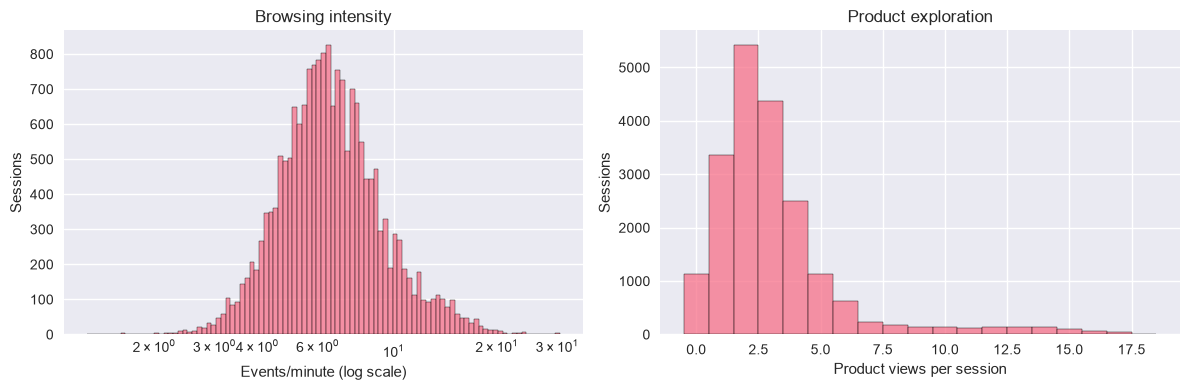

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(X.browse_rate_per_minute, log_scale=True, ax=ax[0])
sns.histplot(X.browse_product_view_count, discrete=True, ax=ax[1])
ax[0].set(title='Browsing intensity', xlabel='Events/minute (log scale)', ylabel='Sessions')
ax[1].set(title='Product exploration', xlabel='Product views per session', ylabel='Sessions')
plt.tight_layout(); plt.show()

## Problem Statement

Rank unusual browsing behavior without labels and evaluate fixed decisions afterward against injected suspicious labels on held-out users. Flags indicate review candidates, never confirmed fraud.

## Numbered Questions

### 1. Which sessions are unusual under label-blind rules and Isolation Forest?
Descriptive unsupervised modeling: H0/H1, statistical power and hypothesis tests do not apply. A fixed 5% training contamination is an analytical review-capacity assumption, unrelated to label prevalence. Hyperparameters and the rule are fixed before evaluation; no label-based tuning occurs.

In [8]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train, test = next(splitter.split(X, groups=features.user_id))
assert not set(features.iloc[train].user_id) & set(features.iloc[test].user_id)
assert len(train) + len(test) == len(features)
imputer = SimpleImputer(strategy='median')
X_train = imputer.fit_transform(X.iloc[train])
X_all = imputer.transform(X)
assert X_train.shape[1] == len(model_columns) and np.isfinite(X_all).all()
print(f'Train sessions: {len(train):,}; held-out sessions: {len(test):,}; no shared users')

Train sessions: 14,044; held-out sessions: 5,956; no shared users


In [9]:
model = IsolationForest(n_estimators=200, max_samples=256, contamination=0.05, random_state=SEED, n_jobs=1)
model.fit(X_train)
features['anomaly_score'] = -model.score_samples(X_all)
features['model_flag'] = (model.predict(X_all) == -1).astype(int)

Fixed transparent rule: flag sessions above the training 99th percentile of browsing rate **or** product-view count. Ties use a strict greater-than comparison. An undefined rate cannot trigger the rate rule; product counts remain usable. Each threshold is label-free; flag proportions need not equal exactly 2% or 5%.

In [10]:
rule_columns = ['browse_rate_per_minute', 'browse_product_view_count']
thresholds = X.iloc[train][rule_columns].quantile(0.99)
features['rule_flag'] = X[rule_columns].gt(thresholds).any(axis=1).astype(int)
features['evaluation_group'] = 'train'
features.loc[test, 'evaluation_group'] = 'held_out'
display(thresholds.rename('training_99th_percentile'))

browse_rate_per_minute       16.433855
browse_product_view_count    14.000000
Name: training_99th_percentile, dtype: float64

### 2. How well do fixed flags recover synthetic labels in held-out users?
Model evaluation exception: report descriptive precision, recall, F1 and confusion matrices; no hypothesis test, power claim or real-world accuracy inference. Correlated sessions within held-out users make naive binomial intervals inappropriate, so metrics are point estimates only. Labels are first loaded below, after all fitting and flagging.

In [11]:
labels = pd.read_csv(RAW / 'sessions.csv', usecols=['session_id', 'ground_truth_suspicious', 'ground_truth_friction', 'scenario'])
assert labels.session_id.is_unique and set(labels.session_id) == set(features.session_id)
evaluated = features.merge(labels, on='session_id', validate='one_to_one')
assert evaluated.ground_truth_suspicious.isin([0, 1]).all()
holdout = evaluated[evaluated.evaluation_group.eq('held_out')]
metrics = []
for flag in ['rule_flag', 'model_flag']:
    precision, recall, f1, _ = precision_recall_fscore_support(holdout.ground_truth_suspicious, holdout[flag], average='binary', zero_division=0)
    tn, fp, fn, tp = confusion_matrix(holdout.ground_truth_suspicious, holdout[flag], labels=[0, 1]).ravel()
    metrics.append({'method':flag, 'precision':precision, 'recall':recall, 'f1':f1,
                    'tn':int(tn), 'fp':int(fp), 'fn':int(fn), 'tp':int(tp), 'false_positive_rate':fp/(fp+tn)})
metrics = pd.DataFrame(metrics)
display(metrics)
print(f'Held-out injected-label prevalence: {holdout.ground_truth_suspicious.mean():.2%}')

,method,precision,recall,f1,tn,fp,fn,tp,false_positive_rate
0,rule_flag,0.949640,0.297297,0.452830,5505,7,312,132,0.001270
1,model_flag,0.926471,0.709459,0.803571,5487,25,129,315,0.004536


Held-out injected-label prevalence: 7.45%


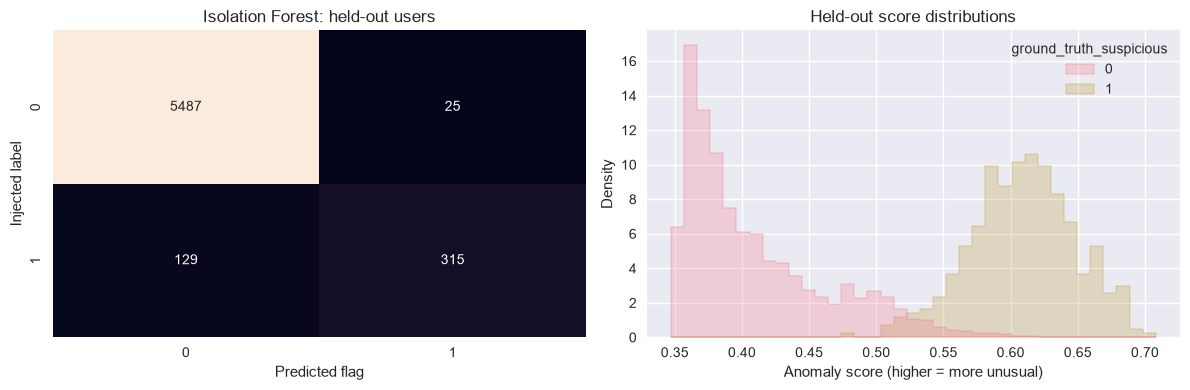

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(holdout.ground_truth_suspicious, holdout.model_flag, labels=[0,1]),
            annot=True, fmt='d', cbar=False, ax=ax[0])
ax[0].set(title='Isolation Forest: held-out users', xlabel='Predicted flag', ylabel='Injected label')
sns.histplot(data=holdout, x='anomaly_score', hue='ground_truth_suspicious', common_norm=False,
             stat='density', element='step', ax=ax[1])
ax[1].set(title='Held-out score distributions', xlabel='Anomaly score (higher = more unusual)', ylabel='Density')
plt.tight_layout(); plt.show()

In [13]:
scenario_review = holdout.groupby('scenario').agg(sessions=('session_id','size'), model_flag_rate=('model_flag','mean'), rule_flag_rate=('rule_flag','mean'))
display(scenario_review.style.format({'model_flag_rate':'{:.2%}', 'rule_flag_rate':'{:.2%}'}))
print('All-session synthetic label count:', int(evaluated.ground_truth_suspicious.sum()))
print('Held-out rule/model flagged sessions:', int(holdout.rule_flag.sum()), int(holdout.model_flag.sum()))

,sessions,model_flag_rate,rule_flag_rate
scenario,,,
automated_repetitive,275,72.36%,31.64%
checkout_friction,651,2.15%,0.15%
high_frequency,169,68.64%,26.63%
navigation_confusion,413,2.66%,0.00%
technical_error,250,0.00%,0.00%
typical,4198,0.00%,0.14%


All-session synthetic label count: 1385
Held-out rule/model flagged sessions: 139 340


The feature export includes derived flags and an evaluation-group identifier but omits ground-truth and scenario columns. Rerunning Notebook 04 selects the same explicit inputs and overwrites its own outputs.

In [14]:
assert features.session_id.is_unique and np.isfinite(features.anomaly_score).all()
assert not any(c.startswith('ground_truth') or c == 'scenario' for c in features.columns)
features.to_csv(PROCESSED / 'session_features.csv', index=False)

## Summary

Use held-out metrics and error counts above to assess this fixed synthetic workflow. Model and percentile rules were trained without labels, using disjoint users for evaluation. Review false positives and false negatives by scenario only after fitting.

In [15]:
display(Markdown(f'**Held-out evaluation:** {len(holdout):,} sessions; Isolation Forest precision {metrics.iloc[1].precision:.3f}, recall {metrics.iloc[1].recall:.3f}, F1 {metrics.iloc[1].f1:.3f}. Review the {int(metrics.iloc[1].fp)} false positives and {int(metrics.iloc[1].fn)} false negatives before further development.'))

**Held-out evaluation:** 5,956 sessions; Isolation Forest precision 0.926, recall 0.709, F1 0.804. Review the 25 false positives and 129 false negatives before further development.

## Insights

Flags are review candidates, not confirmed fake engagement or fraud. Scores are not probabilities. Synthetic labels, arbitrary thresholds and a random user split do not establish real-world or future-time performance. No real unlabeled dataset was supplied. Collect reviewed real examples and a temporal holdout before deployment; do not retune on this held-out set.